# 插值 ― interpolate 模块

## 本章要学什么

插值是由已知的离散数据求出其间各点值的方法，与拟合不同，插值曲线要通过所有数据点。`interpolate` 模块里有一维到多维的插值函数。

- 一维插值(`interp1d()`)
- 外插与平滑(`UnivariateSpline()`)
- 参数曲线的插值(`splprep()`)
- 保单调的插值(`PchipInterpolator`)
- 多维插值(`RegularGridInterpolator`、`griddata()`、`Rbf`)

In [1]:
from matplotlib import pyplot as plt

import helper.matplotlib
import numpy as np
from scipy import interpolate

## 一维插值

一维数据用 `interp1d()` 插值，它的调用形式如下，注意它是一个类而不是函数。

```python
interp1d(x, y, kind='linear', ...)
```

其中 `x` 与 `y` 是已知的数据点，`kind` 是插值的种类。`kind` 表示 B 样条的次数，可以取下面的值。

* `'zero'`、`'nearest'`：阶梯状插值，0 次 B 样条。
* `'slinear'`、`'linear'`：用直线连接各点的插值，1 次 B 样条；`'slinear'` 由扩展库的函数计算、`'linear'` 由 Python 函数计算，但结果相同。
* `'quadratic'`、`'cubic'`：2 次与 3 次 B 样条，次数也可以直接用整数指定。

`interp1d` 对象能计算 `x` 范围内任意点上的值，它可以像函数一样调用，并且和 ufunc 一样对数组的每个元素逐个计算、返回新的数组。

下面的程序画出各种 `kind` 对应的插值曲线：❶ 由数据点做出 `interp1d` 对象 `f`，并用 `kind` 指定次数；❷ 再用 `f()` 算出插值后的值。数据点是 11 个，插值之后是 101 个点。

:::{warning}
高次的 `interp1d()` 计算量会变大，数据点多的时候请改用后面要讲的 `UnivariateSpline()`。
:::

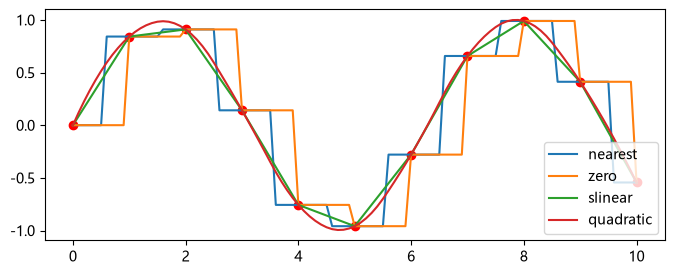

In [2]:
from scipy import interpolate

x = np.linspace(0, 10, 11)
y = np.sin(x)

xnew = np.linspace(0, 10, 101)
plt.figure(figsize=(8, 3))
plt.plot(x, y, "ro")          # 原始数据点
for kind in ["nearest", "zero", "slinear", "quadratic"]:
    f = interpolate.interp1d(x, y, kind=kind)  #❶ 指定插值的种类
    ynew = f(xnew)  #❷ 计算插值后的值
    plt.plot(xnew, ynew, label=str(kind))

plt.legend(loc="lower right")  # 各种 kind 的曲线
plt.show()

### 外插与样条插值

`interp1d` 要求 `x` 是递增的序列，而且只能计算 `x` 范围内的值；计算范围之外叫作外插，用它做不到。

`UnivariateSpline` 的功能比 `interp1d` 更强，能做外插和平滑，调用形式如下。

```python
UnivariateSpline(x, y, w=None, bbox=[None, None], k=3, s=None)
```

* `x`、`y`：数据点的坐标，`x` 必须是递增的序列。
* `w`：各数据点的权重。
* `k`：样条的次数。
* `s`：平滑系数，曲线要满足 $\sum_{i=1}^{n}{(w_i \cdot (y_i-spline(x_i))^2} \leq s$；$s>0$ 时曲线不一定通过数据点，要让曲线通过所有点就把 $s$ 设为 0。

`InterpolatedUnivariateSpline` 则总是通过所有点，效果等同于在 `UnivariateSpline` 里取 `s=0`。

下面的程序确认插值、外插与平滑这三种情况。

❶ 上图是外插的例子：数据只到 x=10，而这里算到了 12。在 10 之后仍能保持类似正弦波的形状，但离数据越远误差越大。所以外插只能用在小范围内；由于取的是 `s=0`，曲线通过所有点。

❷ 下图是把 `s` 取成非零值的例子：即使数据带有噪声，只要 `s` 选得合适，曲线就能贴近没有噪声的波形，可以把它看成用样条对数据做了平滑。

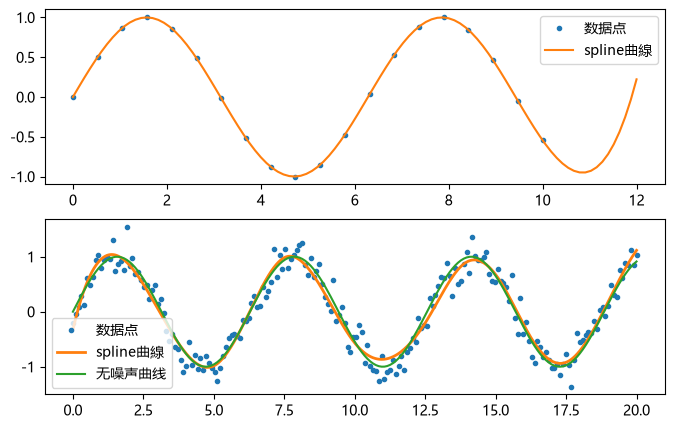

In [3]:
x1 = np.linspace(0, 10, 20)
y1 = np.sin(x1)
sx1 = np.linspace(0, 12, 100)
sy1 = interpolate.UnivariateSpline(x1, y1, s=0)(sx1)  #❶ 通过所有点

x2 = np.linspace(0, 20, 200)
y2 = np.sin(x2) + np.random.standard_normal(len(x2)) * 0.2  # 加入噪声
sx2 = np.linspace(0, 20, 2000)
spline2 = interpolate.UnivariateSpline(x2, y2, s=8)  #❷ 做平滑
sy2 = spline2(sx2)

plt.figure(figsize=(8, 5))
plt.subplot(211)
plt.plot(x1, y1, ".", label="数据点")
plt.plot(sx1, sy1, label="spline曲線")
plt.legend()

plt.subplot(212)
plt.plot(x2, y2, ".", label="数据点")
plt.plot(sx2, sy2, linewidth=2, label="spline曲線")
plt.plot(x2, np.sin(x2), label="无噪声曲线")
plt.legend()
plt.show()

曲线为 3 次时，可以用 `UnivariateSpline.roots()` 算出曲线与 $y=0$ 交点处的 x 坐标，也就是求下图曲线与 x 轴的交点。

In [4]:
print(np.array_str(spline2.roots(), precision=3))

[ 0.161  3.071  6.271  9.298 12.74  15.757 18.814]


想求与任意水平线的交点时，把曲线的系数沿 y 方向平移再算即可。不过每换一条水平线就重新构造一次很麻烦。

❶ 下面的 `roots_at()` 直接改写曲线的系数把曲线平移，再计算交点；❷ 再把它加进 `UnivariateSpline` 的方法里；❸ 最后对几条水平线求交点并画出来。

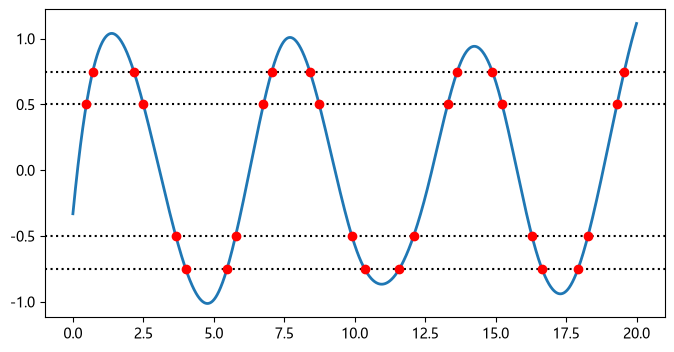

In [5]:
def roots_at(self, v):  #❶ 把系数降低 v，求出交点
    coeff = self.get_coeffs()
    coeff -= v
    try:
        root = self.roots()
        return root
    finally:
        coeff += v


interpolate.UnivariateSpline.roots_at = roots_at  #❷ 作为方法加上去

plt.figure(figsize=(8, 4))
plt.plot(sx2, sy2, linewidth=2, label="spline曲線")

ax = plt.gca()
for level in [0.5, 0.75, -0.5, -0.75]:
    ax.axhline(level, ls=":", color="k")
    xr = spline2.roots_at(level)  #❸
    plt.plot(xr, spline2(xr), "ro")

plt.show()

### 参数曲线插值

到这里的插值都要求 x 是递增的序列，也就是 $y=f(x)$ 这种形状的曲线。而用参数 $t$ 写成 $x=f(t)$、$y=g(t)$ 的曲线叫参数曲线，圆和心形的曲线都属于这一类。

参数曲线的插值用 `splprep()` 与 `splev()` 来做，也能用于更高维的曲线，这里只给二维的例子。

❶ `splprep()` 的第 1 个参数是把各轴坐标排起来的数组组成的列表，`s` 是平滑系数、含义与 `UnivariateSpline` 相同；它返回两个值，`tck` 是汇总了曲线信息的元组，`t` 是自动定出的参数数组。

❷ 用 `splev()` 插值：第 1 个参数是新的参数数组，这里把 `t` 的范围分成 200 等份；第 2 个参数是 `splprep()` 返回的 `tck`。`t` 是把线段长度累加再归一化得到的值，所以范围是 0 到 1。

下图是 `s=0` 与 `s=1e-4` 的插值曲线，其中 `s=0` 时曲线通过所有点。

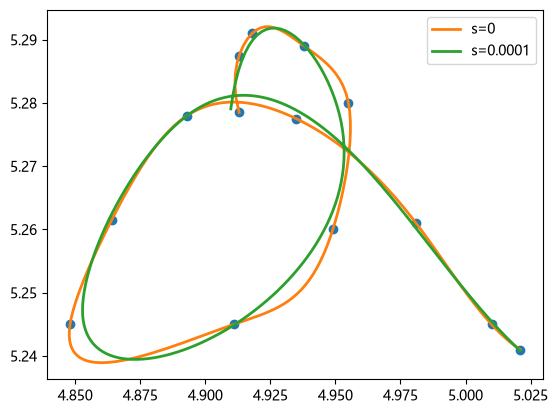

In [6]:
x = [
    4.913,
    4.913,
    4.918,
    4.938,
    4.955,
    4.949,
    4.911,
    4.848,
    4.864,
    4.893,
    4.935,
    4.981,
    5.01,
    5.021,
]

y = [
    5.2785,
    5.2875,
    5.291,
    5.289,
    5.28,
    5.26,
    5.245,
    5.245,
    5.2615,
    5.278,
    5.2775,
    5.261,
    5.245,
    5.241,
]

plt.plot(x, y, "o")

for s in (0, 1e-4):
    tck, t = interpolate.splprep([x, y], s=s)  #❶ 曲线的信息与参数
    xi, yi = interpolate.splev(np.linspace(t[0], t[-1], 200), tck)  #❷ 插值
    plt.plot(xi, yi, lw=2, label=f"s={s:g}")

plt.legend()
plt.show()

### 保单调插值

到这里的插值都不能保证数据的单调性，曲线的极值有时会出现在数据点以外的地方。

`PchipInterpolator`(别名 `pchip`)做的是保单调的三次插值，它能让曲线的极值只落在数据点上。下面的程序画出 `pchip()` 的插值曲线及其一阶导数，可以看到导数在极值处正好为 0。

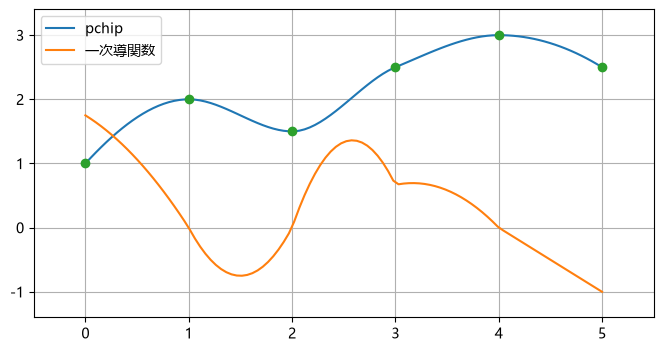

In [7]:
x = [0, 1, 2, 3, 4, 5]
y = [1, 2, 1.5, 2.5, 3, 2.5]
xs = np.linspace(x[0], x[-1], 100)
curve = interpolate.pchip(x, y)  # 保单调的三次插值
ys = curve(xs)
dys = curve.derivative()(xs)     # 1 次導関数
plt.figure(figsize=(8, 4))
plt.plot(xs, ys, label="pchip")
plt.plot(xs, dys, label="一次導関数")
plt.plot(x, y, "o")
plt.legend(loc="best")
plt.grid()
plt.margins(0.1, 0.1)
plt.show()

## 多维插值

`RegularGridInterpolator` 对规则网格(不要求等间隔)上的数据做插值，一维到三维以上都能用，主要参数如下。

| 参数 | 说明 |
|------|------|
| `points` | 各维的网格点，像 `(x, y, z, ...)` 那样按维把数组排起来。 |
| `values` | 各网格点上的值，形状与 `points` 对应的多维数组。 |
| `method` | `"linear"`(默认)、`"cubic"`、`"nearest"` 三者之一。 |

下面的例子在二维上对曲面的网格点做插值，左边是插值前、右边是插值后。

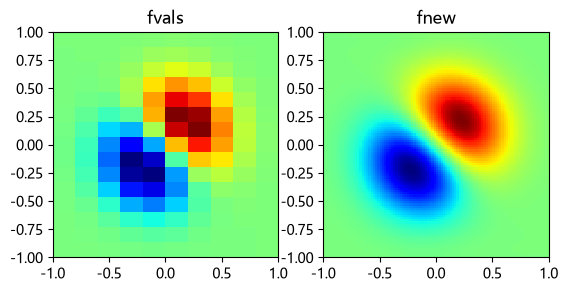

In [8]:
def func(x, y):  #❶ 曲面的高度
    return (x + y) * np.exp(-5.0 * (x**2 + y**2))


y, x = np.ogrid[-1:1:15j, -1:1:10j]  #❷ 15×10 的网格
fvals = func(x, y)

interp_func = interpolate.RegularGridInterpolator(  #❸ 准备插值
    (y.ravel(), x.ravel()), fvals, method="cubic"
)

Ynew, Xnew = np.ogrid[-1:1:100j, -1:1:100j]
fnew = interp_func((Xnew, Ynew))  # 在 100×100 上插值  #❹ 用更细的网格插值

plt.subplot(121)
plt.imshow(
    fvals,
    extent=[-1, 1, -1, 1],
    cmap=plt.cm.jet,
    interpolation="nearest",
    origin="lower",
)
plt.title("fvals")
plt.subplot(122)
plt.imshow(
    fnew,
    extent=[-1, 1, -1, 1],
    cmap=plt.cm.jet,
    interpolation="nearest",
    origin="lower",
)
plt.title("fnew")
plt.show()

❶ `func` 是返回曲面高度的函数。❷ 在 -1 到 1 之间用 15×10 的等间隔网格计算 x 与 y，结果的 `fvals` 中第 0 轴对应 y、第 1 轴对应 x。❸ 由网格坐标与值建立 `RegularGridInterpolator`，这里用三次插值。❹ 这个对象能像函数一样调用，于是就用更细的网格算出高度。

### griddata

`RegularGridInterpolator` 只处理规则网格上的数据，而要对散乱分布的点插值就要用 `griddata()`，调用形式如下。

```python
griddata(points, values, xi, method='linear', fill_value=nan)
```

其中 `points` 是 k 维空间中的坐标，可以是形状 `(N, k)` 的数组、也可以是 k 个数组组成的序列；`values` 是各点上的值，`xi` 是要插值的坐标(形状 `(M, k)`)；`method` 从 `'nearest'`、`'linear'`、`'cubic'` 里选。

下面的程序做了试验：左边是 `'nearest'`，每个点取最近数据点的值。所以会出现一块块同色的方块；`'linear'` 与 `'cubic'` 只在数据点凸包内部插值，外部取 `fill_value`，中图与右图里的白色部分就是凸包之外。

:::{warning}
`griddata()` 用欧氏距离插值，当 k 维空间里各维的取值范围相差很大时，请先把数据归一化再使用。
:::

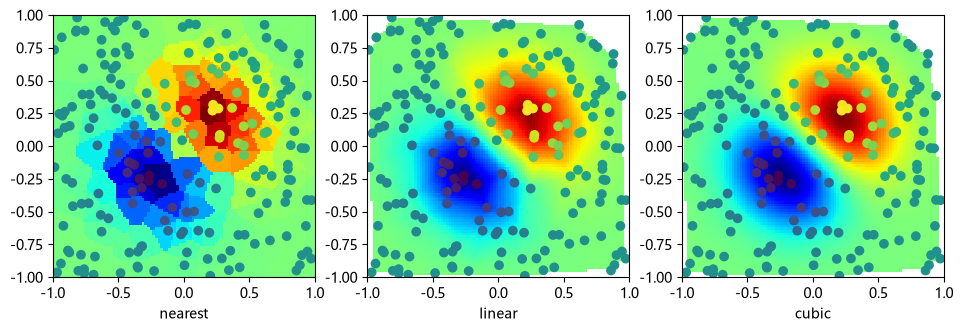

In [9]:
# N 个随机点的坐标，以及这些点上的函数值
N = 200
np.random.seed(42)
x = np.random.uniform(-1, 1, N)
y = np.random.uniform(-1, 1, N)
z = func(x, y)

yg, xg = np.mgrid[-1:1:100j, -1:1:100j]
xi = np.c_[xg.ravel(), yg.ravel()]

methods = "nearest", "linear", "cubic"

zgs = [
    interpolate.griddata((x, y), z, xi, method=method).reshape(100, 100)
    for method in methods
]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))

for ax, method, zg in zip(axes, methods, zgs):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel(method)
    ax.scatter(x, y, c=z)

plt.show()

### 径向基函数插值

径向基函数(RBF)插值也能用于散乱点的插值(包括高维)，所谓径向基函数，是指取值只由与某点的距离决定的函数 $\phi(\left\| \mathbf{x} - \mathbf{x}_i \right\|)$，其中 $\mathbf{x}_i$ 是给定的数据点。把这些函数叠加起来，就逼近了 N 维空间中的函数。

$$y(\mathbf{x}) = \sum_{i=1}^N w_i \, \phi(\|\mathbf{x} - \mathbf{x}_i\|)$$

先看一维的情形：下图是用 `multiquadric`、`gaussian`、`linear` 三种基函数插值的结果。

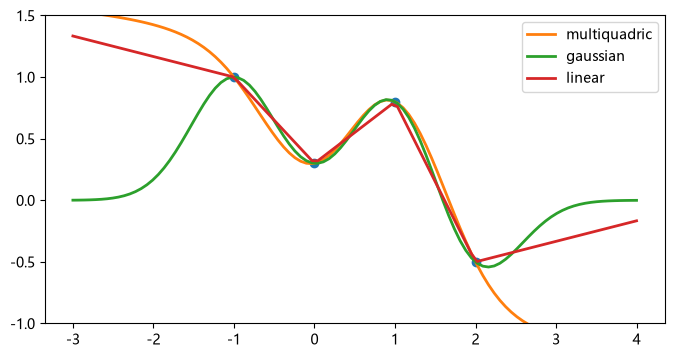

In [10]:
from scipy.interpolate import Rbf

x1 = np.array([-1, 0, 2.0, 1.0])
y1 = np.array([1.0, 0.3, -0.5, 0.8])

funcs = ["multiquadric", "gaussian", "linear"]
nx = np.linspace(-3, 4, 100)
rbfs = [Rbf(x1, y1, function=fname) for fname in funcs]  #❶ 对每种基函数分别插值
rbf_ys = [rbf(nx) for rbf in rbfs]  #❷ 计算插值后的值

plt.figure(figsize=(8, 4))
plt.plot(x1, y1, "o")
for fname, ny in zip(funcs, rbf_ys):
    plt.plot(nx, ny, label=fname, lw=2)

plt.ylim(-1.0, 1.5)
plt.legend()
plt.show()

❶ 由数据点 `x1`、`y1` 建立 `Rbf` 对象，并用 `function` 选择基函数。❷ 这个对象能像函数一样调用，于是算出 `nx` 各位置上的值。

系数 $w_i$ 放在 `Rbf` 的 `nodes` 属性里。

In [11]:
for fname, rbf in zip(funcs, rbfs):
    print(fname, rbf.nodes)

multiquadric [-0.88822885  2.17654513  1.42877511 -2.67919021]
gaussian [ 1.00321945 -0.02345964 -0.65441716  0.91375159]
linear [-0.26666667  0.6         0.73333333 -0.9       ]


下面是二维的例子。

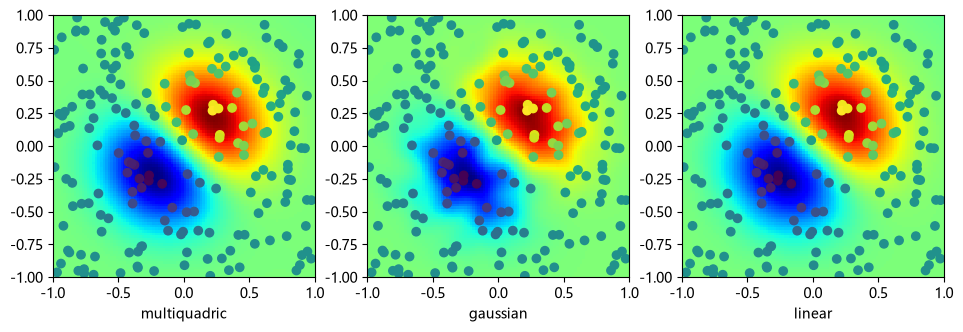

In [12]:
rbfs = [Rbf(x, y, z, function=fname) for fname in funcs]
rbf_zg = [rbf(xg, yg).reshape(xg.shape) for rbf in rbfs]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, fname, zg in zip(axes, funcs, rbf_zg):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel(fname)
    ax.scatter(x, y, c=z)

plt.show()

有些基函数可以用 `epsilon` 指定影响的范围：值越大，各点的影响范围越宽，曲面也越光滑。下面的代码改变 `gaussian` 的 `epsilon` 作比较。

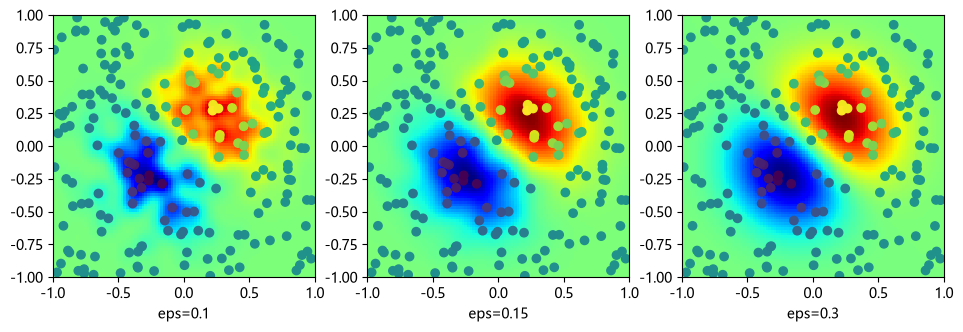

In [13]:
epsilons = 0.1, 0.15, 0.3
rbfs = [Rbf(x, y, z, function="gaussian", epsilon=eps) for eps in epsilons]
zgs = [rbf(xg, yg).reshape(xg.shape) for rbf in rbfs]

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.5))
for ax, eps, zg in zip(axes, epsilons, zgs):
    ax.imshow(
        zg,
        extent=[-1, 1, -1, 1],
        cmap=plt.cm.jet,
        interpolation="nearest",
        origin="lower",
    )
    ax.set_xlabel("eps=%g" % eps)
    ax.scatter(x, y, c=z)

plt.show()

## 小结

* 一维插值用 `interp1d()`，用 `kind` 选次数与方法，范围之外算不了。
* 需要外插和平滑时用 `UnivariateSpline()`，`s=0` 通过所有点，`s>0` 则做平滑。
* 参数曲线用 `splprep()` 与 `splev()` 插值。
* 想保持单调性时用 `pchip()`。
* 规则网格用 `RegularGridInterpolator`，散乱的点用 `griddata()` 或 `Rbf`。